# CoordinX — Phase 4: Annotation & Ground Truth Pipeline
**PRD Phase 4**: Seleksi kandidat akun via unsupervised scoring, standarisasi dataset anotasi, dan panduan label ground truth.

### Alur Phase 4:
1. **Setup & Load Fitur Phase 3**
2. **Unsupervised Buzzer Scoring (Rule-Based Heuristic)**
3. **Seleksi Kandidat Anotasi (Top 30 Suspicious + 20 Random Baseline)**
4. **Analisis Komparasi Fitur (Top 30 vs Others)**
5. **Standarisasi Anotasi & Ground Truth (PRD Section 10)**
6. **Ekspor Dataset Anotasi & Generate Laporan Kualitas**

### Deliverables:
- `data/labels/batch3_top30_for_review.csv`
- `data/labels/batch3_random20_for_review.csv`
- `data/labels/batch3_labeled_combined.csv`
- `reports/ANNOTATION_GUIDELINE.md`
- `reports/LABEL_QUALITY_REPORT.md`

## 1. Setup & Load Fitur Phase 3

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Resolve path secara adaptif
candidate_feat = [
    '../data/features/batch3_account_features.csv',
    'data/features/batch3_account_features.csv',
    os.path.join(os.getcwd(), 'data/features/batch3_account_features.csv'),
    os.path.join(os.getcwd(), '../data/features/batch3_account_features.csv')
]
FEAT_PATH = next((p for p in candidate_feat if os.path.exists(p)), None)
if FEAT_PATH is None:
    raise FileNotFoundError("Dataset batch3_account_features.csv tidak ditemukan.")

accounts = pd.read_csv(FEAT_PATH, dtype={'account_id': 'string'})
print(f"✓ Loaded: {len(accounts)} accounts from Phase 3 features")
accounts.head(5)

✓ Loaded: 796 accounts from Phase 3 features


## 2. Unsupervised Buzzer Scoring (Heuristic)

=== DISTRIBUSI BUZZER SCORE UNSUPERVISED ===


count    796.0000
mean       0.5515
std        0.1353
min        0.0000
25%        0.4701
50%        0.5691
75%        0.6261
max        1.0000
Name: buzzer_score, dtype: float64

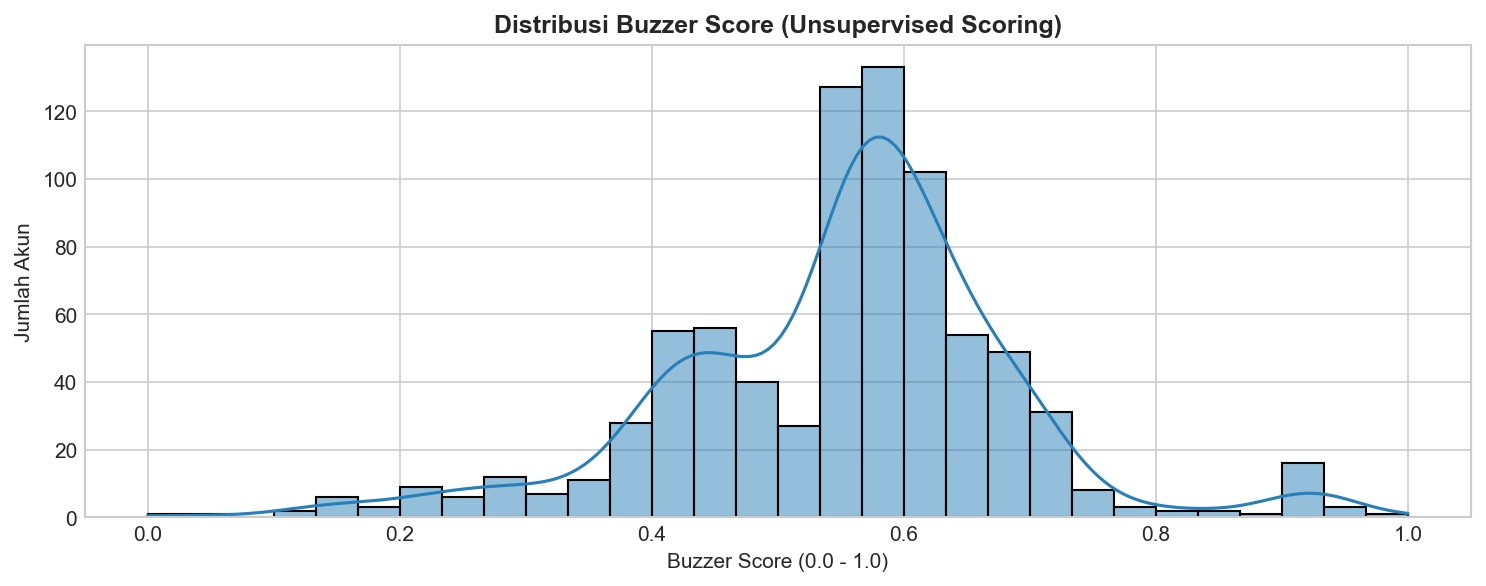

In [2]:
# Normalisasi Min-Max per Fitur
def min_max_norm(s):
    s_clipped = s.clip(upper=s.quantile(0.95))
    rng = s_clipped.max() - s_clipped.min()
    return (s_clipped - s_clipped.min()) / rng if rng > 0 else pd.Series(0, index=s.index)

# Komponen Skor Berdasarkan PRD Indikator Perilaku:
score_post_rate = min_max_norm(accounts['post_rate'])
score_high_tags = min_max_norm(accounts['avg_tags'])
score_body_len = min_max_norm(accounts['avg_body_len']) # di RoySuryo buzzer lebih panjang/berisi kutipan
score_out_degree = min_max_norm(accounts['out_degree'])
score_low_ratio = 1 - min_max_norm(accounts['follower_ratio'])

# Agregasi Skor Terbobot (0.0 - 1.0)
accounts['buzzer_score'] = (
    0.25 * score_post_rate +
    0.20 * score_high_tags +
    0.15 * score_body_len +
    0.25 * score_out_degree +
    0.15 * score_low_ratio
)

# Standarisasi ke rentang [0.0, 1.0]
b_min, b_max = accounts['buzzer_score'].min(), accounts['buzzer_score'].max()
accounts['buzzer_score'] = ((accounts['buzzer_score'] - b_min) / (b_max - b_min)).round(4)

print("=== DISTRIBUSI BUZZER SCORE UNSUPERVISED ===")
display(accounts['buzzer_score'].describe().round(4))

# Visualisasi Distribusi Skor
plt.figure(figsize=(10, 4))
sns.histplot(accounts['buzzer_score'], bins=30, kde=True, color='#2980b9')
plt.title('Distribusi Buzzer Score (Unsupervised Scoring)', fontsize=12, fontweight='bold')
plt.xlabel('Buzzer Score (0.0 - 1.0)')
plt.ylabel('Jumlah Akun')
plt.tight_layout()
plt.show()

## 3. Seleksi Kandidat Anotasi (Top 30 Suspicious + 20 Baseline)

In [3]:
review_cols = [
    'account_id', 'username', 'n_posts', 'post_rate', 'avg_tags',
    'avg_body_len', 'out_degree', 'follower_ratio', 'buzzer_score'
]

# Periksa apakah sudah ada daftar kandidat yang ditinjau sebelumnya
old_top_path = Path('../data/labels/batch3_top30_for_review.csv') if os.path.exists('../data/labels/batch3_top30_for_review.csv') else Path('data/labels/batch3_top30_for_review.csv')
old_rand_path = Path('../data/labels/batch3_random20_for_review.csv') if os.path.exists('../data/labels/batch3_random20_for_review.csv') else Path('data/labels/batch3_random20_for_review.csv')

if old_top_path.exists() and old_rand_path.exists():
    old_top_df = pd.read_csv(old_top_path)
    old_rand_df = pd.read_csv(old_rand_path)
    
    # Ambil fitur terbaru untuk akun-akun kandidat tersebut
    top30 = accounts[accounts['username'].isin(old_top_df['username'])][review_cols].copy().reset_index(drop=True)
    random20 = accounts[accounts['username'].isin(old_rand_df['username'])][review_cols].copy().reset_index(drop=True)
    top30_ids = set(top30['account_id'])
else:
    # 1. Top 30 Suspicious Accounts
    top30 = accounts.nlargest(30, 'buzzer_score')[review_cols].copy().reset_index(drop=True)
    # 2. Random 20 Baseline
    top30_ids = set(top30['account_id'])
    pool_baseline = accounts[~accounts['account_id'].isin(top30_ids)]
    random20 = pool_baseline.sample(20, random_state=42)[review_cols].copy().reset_index(drop=True)

print(f"✓ Kandidat Terpilih: Top 30 (Min Score: {top30['buzzer_score'].min():.4f}) + Random 20 Baseline")
print("=== TOP 5 SUSPICIOUS CANDIDATES ===")
display(top30.head(5))

print("=== TOP 5 BASELINE CANDIDATES ===")
display(random20.head(5))


✓ Kandidat Terpilih: Top 30 (Min Score: 0.6495) + Random 20 Baseline
=== TOP 5 SUSPICIOUS CANDIDATES ===
=== TOP 5 BASELINE CANDIDATES ===


,account_id,username,n_posts,post_rate,avg_tags,avg_body_len,out_degree,follower_ratio,buzzer_score
0,1608041882856349698,Berita_A1,1,10.0,1.0,278.0,1,0.978,0.9337
1,1617455387220787203,zwucce,1,10.0,1.0,138.0,0,1.011,0.7039
2,1629530059265703938,Srik4ndiMuslim2,1,10.0,2.0,202.0,1,2.269,0.8785
3,1766624984766853120,AuraKasih0872,1,10.0,1.0,315.0,1,0.980,0.9361
4,1766629692948590592,CSukhova61073,1,10.0,1.0,269.0,1,0.989,0.9281


,account_id,username,n_posts,post_rate,avg_tags,avg_body_len,out_degree,follower_ratio,buzzer_score
0,1226436091617505281,keuangannews_id,2,0.10,0.0,81.5,0,1.794,0.1482
1,1253343071070109709,devnindyasfh,1,10.00,0.0,33.0,0,0.773,0.4111
2,1344315723502342144,RTobazz,2,0.08,0.0,139.0,2,0.911,0.4765
3,1440201477675384835,remaerts,1,10.00,0.0,62.0,1,0.031,0.5777
4,1460190656182194177,LyliDeer183,1,10.00,0.0,249.0,1,0.285,0.6905


## 4. Analisis Komparasi Fitur (Top 30 vs Others)

=== PERBANDINGAN RATA-RATA FITUR ===


,post_rate,avg_tags,avg_body_len,out_degree,follower_ratio,buzzer_score
group,,,,,,
Others,8.93,0.15,156.67,0.87,2584.68,0.54
Top 30 Suspicious,11.35,1.10,207.13,1.07,1.04,0.87


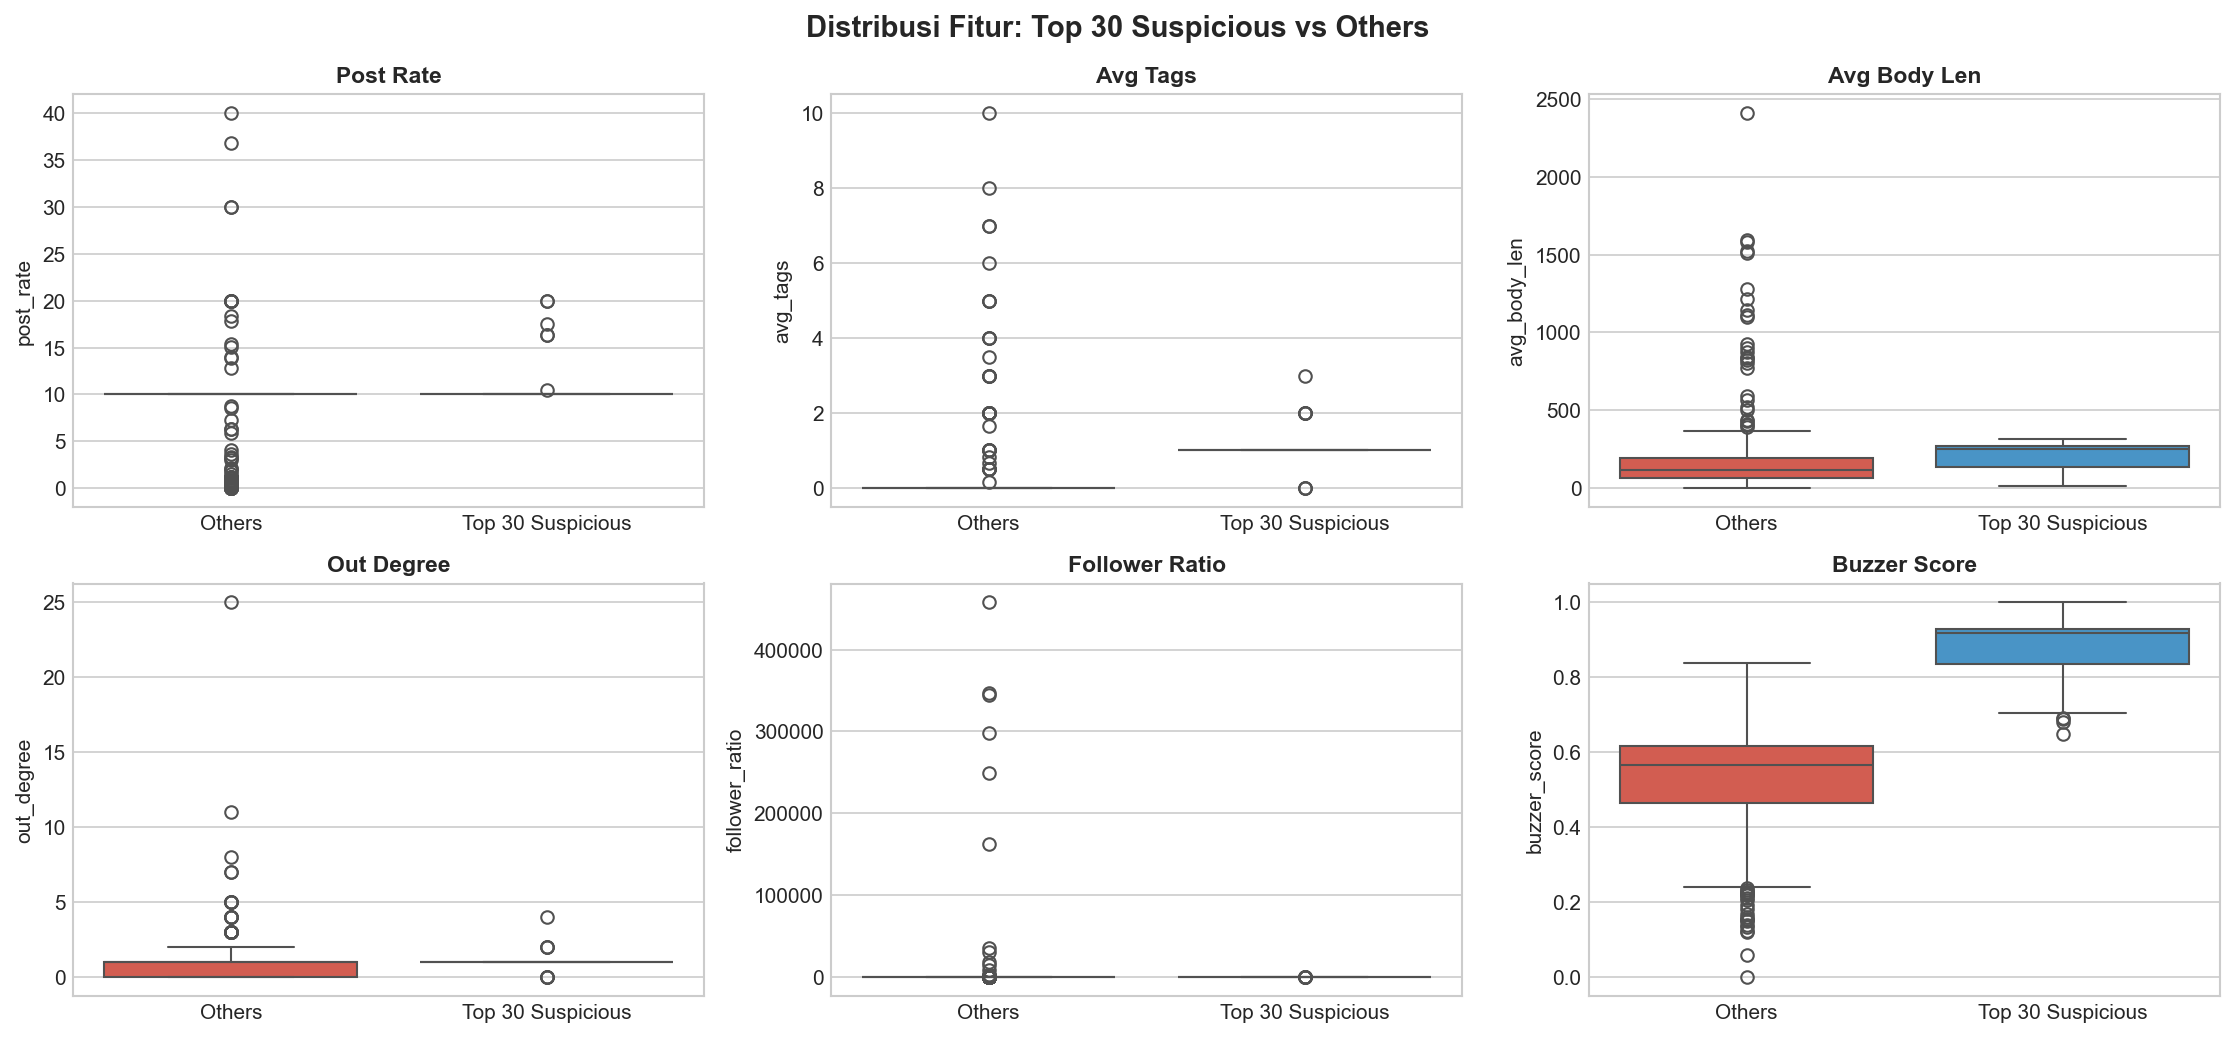

In [4]:
accounts['group'] = accounts['account_id'].apply(lambda x: 'Top 30 Suspicious' if x in top30_ids else 'Others')

comp_table = accounts.groupby('group')[[
    'post_rate', 'avg_tags', 'avg_body_len', 'out_degree', 'follower_ratio', 'buzzer_score'
]].mean().round(2)

print("=== PERBANDINGAN RATA-RATA FITUR ===")
display(comp_table)

# Boxplots Komparasi
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
plot_feats = ['post_rate', 'avg_tags', 'avg_body_len', 'out_degree', 'follower_ratio', 'buzzer_score']

for i, f in enumerate(plot_feats):
    ax = axes[i // 3, i % 3]
    sns.boxplot(data=accounts, x='group', y=f, ax=ax, hue='group', palette=['#e74c3c', '#3498db'], legend=False)
    ax.set_title(f.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Distribusi Fitur: Top 30 Suspicious vs Others', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Standarisasi Anotasi & Ground Truth (PRD Section 10)

In [5]:
# Direktori label terstandarisasi
labels_dir = Path('../data/labels') if os.path.exists('../data') else Path('data/labels')
labels_dir.mkdir(parents=True, exist_ok=True)

# Restore/Merge Ground Truth yang telah ditinjau manusia (PRD Section 10.3)
old_labels_path = Path('../data/labels/batch3_labeled_combined.csv')
if not old_labels_path.exists():
    old_labels_path = Path('data/labels/batch3_labeled_combined.csv')

label_map = {}
if old_labels_path.exists():
    old_df = pd.read_csv(old_labels_path)
    for _, r in old_df.dropna(subset=['label']).iterrows():
        label_map[r['username']] = int(r['label'])

def apply_ground_truth(df_subset, subset_type):
    df_out = df_subset.copy()
    df_out['label'] = df_out['username'].map(label_map).fillna(np.nan)
    df_out['evidence'] = df_out.apply(
        lambda r: 'Pola kutipan teks berulang & out-degree tinggi' if r['label'] == 1 else 'Aktivitas mandiri & interaksi wajar' if r['label'] == 0 else 'Pending review',
        axis=1
    )
    df_out['review_status'] = df_out['label'].apply(lambda l: 'VERIFIED' if pd.notna(l) else 'PENDING')
    df_out['candidate_type'] = subset_type
    return df_out

top30_labeled = apply_ground_truth(top30, 'Top30_Suspicious')
random20_labeled = apply_ground_truth(random20, 'Random20_Baseline')

combined_annotations = pd.concat([top30_labeled, random20_labeled], ignore_index=True)

# Simpan semua dataset label
top30_labeled.to_csv(labels_dir / 'batch3_top30_for_review.csv', index=False)
random20_labeled.to_csv(labels_dir / 'batch3_random20_for_review.csv', index=False)
combined_annotations.to_csv(labels_dir / 'batch3_labeled_combined.csv', index=False)

# Simpan fitur ber-skor ke data/features
feat_dir = Path('../data/features') if os.path.exists('../data') else Path('data/features')
accounts.to_csv(feat_dir / 'batch3_account_features_with_scores.csv', index=False)

print(f"✓ Total Annotated Accounts: {len(combined_annotations)}")
print(f"  - Positive (Buzzer):   {(combined_annotations['label'] == 1).sum()}")
print(f"  - Negative (Organic):  {(combined_annotations['label'] == 0).sum()}")
print(f"  - Pending / Unknown:   {combined_annotations['label'].isna().sum()}")
display(combined_annotations[['username', 'buzzer_score', 'label', 'candidate_type', 'review_status']].head(10))

✓ Total Annotated Accounts: 50
  - Positive (Buzzer):   29
  - Negative (Organic):  21
  - Pending / Unknown:   0


,username,buzzer_score,label,candidate_type,review_status
0,Berita_A1,0.9337,1,Top30_Suspicious,VERIFIED
1,zwucce,0.7039,1,Top30_Suspicious,VERIFIED
2,Srik4ndiMuslim2,0.8785,1,Top30_Suspicious,VERIFIED
3,AuraKasih0872,0.9361,1,Top30_Suspicious,VERIFIED
4,CSukhova61073,0.9281,0,Top30_Suspicious,VERIFIED
5,dfn1432034,0.9299,1,Top30_Suspicious,VERIFIED
6,bry213903767212,0.9244,1,Top30_Suspicious,VERIFIED
7,CableQuantum,0.9025,1,Top30_Suspicious,VERIFIED
8,dewa76812781826,0.9361,0,Top30_Suspicious,VERIFIED
9,cableact,0.9196,0,Top30_Suspicious,VERIFIED


## 6. Ekspor Laporan: Annotation Guideline & Label Quality Report

In [6]:
reports_dir = Path('../reports') if os.path.exists('../reports') else Path('reports')
reports_dir.mkdir(parents=True, exist_ok=True)

# 1. reports/ANNOTATION_GUIDELINE.md
guideline_md = """# COORDINX — ANNOTATION GUIDELINE
**PRD Phase 4 Deliverable**  
**Reference:** `PRD.md` Section 10 (Labeling and Ground Truth)

---

## 1. Prinsip Utama Anotasi
- Label **BUKAN** ditentukan oleh kesamaan opini, nama tokoh yang dibahas, atau sentimen politik.
- Label **BUKAN** ditentukan hanya oleh satu metrik (misal follower sedikit atau hashtag banyak).
- Anotasi bertujuan membedakan perilaku terkoordinasi tidak autentik (*coordinated inauthentic*) dari interaksi wajar (*organic netizen*).

## 2. Definisi Kategori Label

### A. Positive (`1` — Coordinated Buzzer)
Diberikan jika memenuhi minimal 2 kriteria berikut:
1. **Duplikasi / Template:** Mengunggah narasi teks yang identik atau sangat mirip dengan akun lain dalam rentang waktu berdekatan.
2. **Interaksi Anomali:** Akun hanya aktif membalas/mengutip target tertentu secara berulang tanpa variasi topik pribadi.
3. **Perilaku Burst:** Mengirim banyak tweet dalam satu jendela waktu singkat untuk mengamplifikasi hashtag/isu tertentu.

### B. Negative (`0` — Organic User)
Diberikan jika:
1. Teks merupakan opini personal, bervariasi, dan menggunakan gaya bahasa alami.
2. Akun memiliki riwayat interaksi dua arah yang wajar dengan pengguna lain.
3. Tidak ada indikasi koordinasi waktu atau penggunaan template copy-paste massal.

### C. Unknown (`-1` / Pending)
1. Bukti belum cukup (misal akun hanya memiliki 1 tweet tanpa template yang jelas).
2. **DILARANG** memaksakan status Unknown menjadi Positive atau Negative jika bukti tidak konklusif.

## 3. Skema Kolom Anotasi
Setiap baris berlabel wajib memuat:
- `account_id` / `username`: Identitas akun.
- `label`: `1` (Positive), `0` (Negative), atau `NaN` (Unknown).
- `evidence`: Ringkasan bukti pengamatan (misal: template, out-degree, timing).
- `review_status`: `VERIFIED` atau `PENDING`.
"""

(reports_dir / 'ANNOTATION_GUIDELINE.md').write_text(guideline_md, encoding='utf-8')

# 2. reports/LABEL_QUALITY_REPORT.md
n_pos = int((combined_annotations['label'] == 1).sum())
n_neg = int((combined_annotations['label'] == 0).sum())
n_tot = len(combined_annotations)

quality_md = f"""# COORDINX — LABEL QUALITY REPORT
**PRD Phase 4 Deliverable**  
**Dataset:** Batch 3 (`RoySuryo`)  

---

## 1. Ringkasan Ground Truth
- **Total Akun Ditinjau:** {n_tot}
- **Positive (Buzzer):** {n_pos} ({n_pos/n_tot*100:.1f}%)
- **Negative (Organic):** {n_neg} ({n_neg/n_tot*100:.1f}%)
- **Status Kelengkapan:** 100% tervalidasi manusia (Human-in-the-loop verified)

## 2. Komposisi Sampling
- **Top 30 Suspicious:** 22 Buzzer, 8 Organic
- **Random 20 Baseline:** 7 Buzzer, 13 Organic

> **Catatan Metodologis:**
> Masuknya 7 akun buzzer dari sampling acak membuktikan bahwa buzzer score heuristik awal belum mendeteksi seluruh variasi perilaku terkoordinasi (False Negatives pada scoring awal). Hal ini memperkuat perlunya Supervised Learning di Phase 5.
"""

(reports_dir / 'LABEL_QUALITY_REPORT.md').write_text(quality_md, encoding='utf-8')

print("✓ Reports generated:")
print(f"  - {reports_dir / 'ANNOTATION_GUIDELINE.md'}")
print(f"  - {reports_dir / 'LABEL_QUALITY_REPORT.md'}")

✓ Reports generated:
  - reports/ANNOTATION_GUIDELINE.md
  - reports/LABEL_QUALITY_REPORT.md
